In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_pickle('../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 4]
df["blockID"] = df["blockID"].astype(str)
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID
0,E162956,2018-04-01,1.62,1.45,1.44,1.59,1.18,0.75,0.95,0.80,0.79,0.75,0.76,0.77,0.89,0.78,1.16,2.04,3.90,2.18,0.80,0.34,0.31,0.13,0.14,0.26,0.22,0.38,0.14,0.29,0.11,0.14,0.16,0.15,0.26,0.14,0.17,0.17,0.19,0.28,0.24,0.17,0.17,0.14,0.22,0.30,0.14,0.13,0.15,0.31,46.0,POINT (-84.30334 30.388433),1801.0,18011011.0
1,E162956,2018-04-02,0.17,0.15,0.16,0.27,0.13,0.16,0.11,0.13,0.29,0.12,0.14,0.10,0.31,0.09,0.18,0.55,0.88,0.60,0.54,0.52,0.88,0.21,0.61,1.87,2.68,2.51,2.52,2.25,0.17,0.42,0.18,0.18,0.31,0.22,0.33,0.27,0.66,0.11,0.42,0.49,1.00,0.92,0.26,0.34,0.64,0.21,0.38,0.16,46.0,POINT (-84.30334 30.388433),1801.0,18011011.0


In [3]:
# df1 = pd.read_csv("../../Data/household_data/badge_location.csv")
# df1["blockID"] = df1[["tractID", "blockID"]].apply(
#     lambda x: str(x["tractID"]) + str(x["blockID"]),
#     axis=1,
# )
# df1["blockID"] = df1["blockID"].astype(str)
# df1["tractID"] = df1["tractID"].astype(str)
# df1.to_csv("../../Data/household_data/badge_location.csv",index=False)

In [4]:
boundary_block = pd.read_csv('../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [5]:
import pandas as pd
import numpy as np

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]

# ① 只留必要列，算「有记录日」的日用电
slim = df[["badge", "blockID", "date"] + value_cols].copy()
slim["date"] = pd.to_datetime(slim["date"], errors="coerce").dt.normalize()
slim["blockID"] = pd.to_numeric(slim["blockID"], errors="coerce")
slim = slim.dropna(subset=["badge", "blockID", "date"])
slim = slim.drop_duplicates(subset=["badge", "blockID", "date"], keep="first")

slim["daily_kwh"] = slim[value_cols].fillna(0.0).sum(axis=1)
slim = slim.drop(columns=value_cols)   # 立刻丢掉 48 列，省内存

# ② 每个 badge 一个「日均用电」（只在有记录日上平均）
badge_daily = (
    slim.groupby("badge", as_index=False)
    .agg(
        badge_mean_daily_kwh=("daily_kwh", "mean"),
        blockID=("blockID", "first"),   # 一户一般固定一个 block；若不确定可改成 lambda x: x.mode().iloc[0]
    )
)

# ③ 每个 block：对该 block 内各户的 badge_mean 再平均
block_statistics = (
    badge_daily.groupby("blockID", as_index=False)["badge_mean_daily_kwh"]
    .mean()
    .rename(columns={"badge_mean_daily_kwh": "block_avg_household_daily_kwh"})
)

# 可选：删掉中间大表
# del slim, df

In [6]:
block_statistics.columns = ['blockID','daily_kwh']
geo = geopd.GeoDataFrame(boundary_block).copy()
geo_data = geo.merge(
    block_statistics,
    left_on="blockID",
    right_on="blockID",
    how="left",
)
geo_data = geo_data.dropna(subset=["daily_kwh"])
geo_data.head()

,tractID,blockID,geoID,geometry,centroid,daily_kwh
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094),25.002341
2,1901,19011015,120730019011015,"POLYGON ((-84.32835 30.41138, -84.32818 30.411...",POINT (-84.31403 30.41059),78.049756
3,1001,10011012,120730010011012,"POLYGON ((-84.28204 30.42082, -84.28203 30.421...",POINT (-84.28134 30.4207),116.842587
5,2513,25131028,120730025131028,"POLYGON ((-84.182 30.45348, -84.18156 30.4536,...",POINT (-84.16225 30.44439),23.163803
6,2201,22012016,120730022012016,"POLYGON ((-84.36123 30.46574, -84.36122 30.465...",POINT (-84.35789 30.46551),184.962048


In [7]:
print(geo_data['blockID'].nunique())

2559


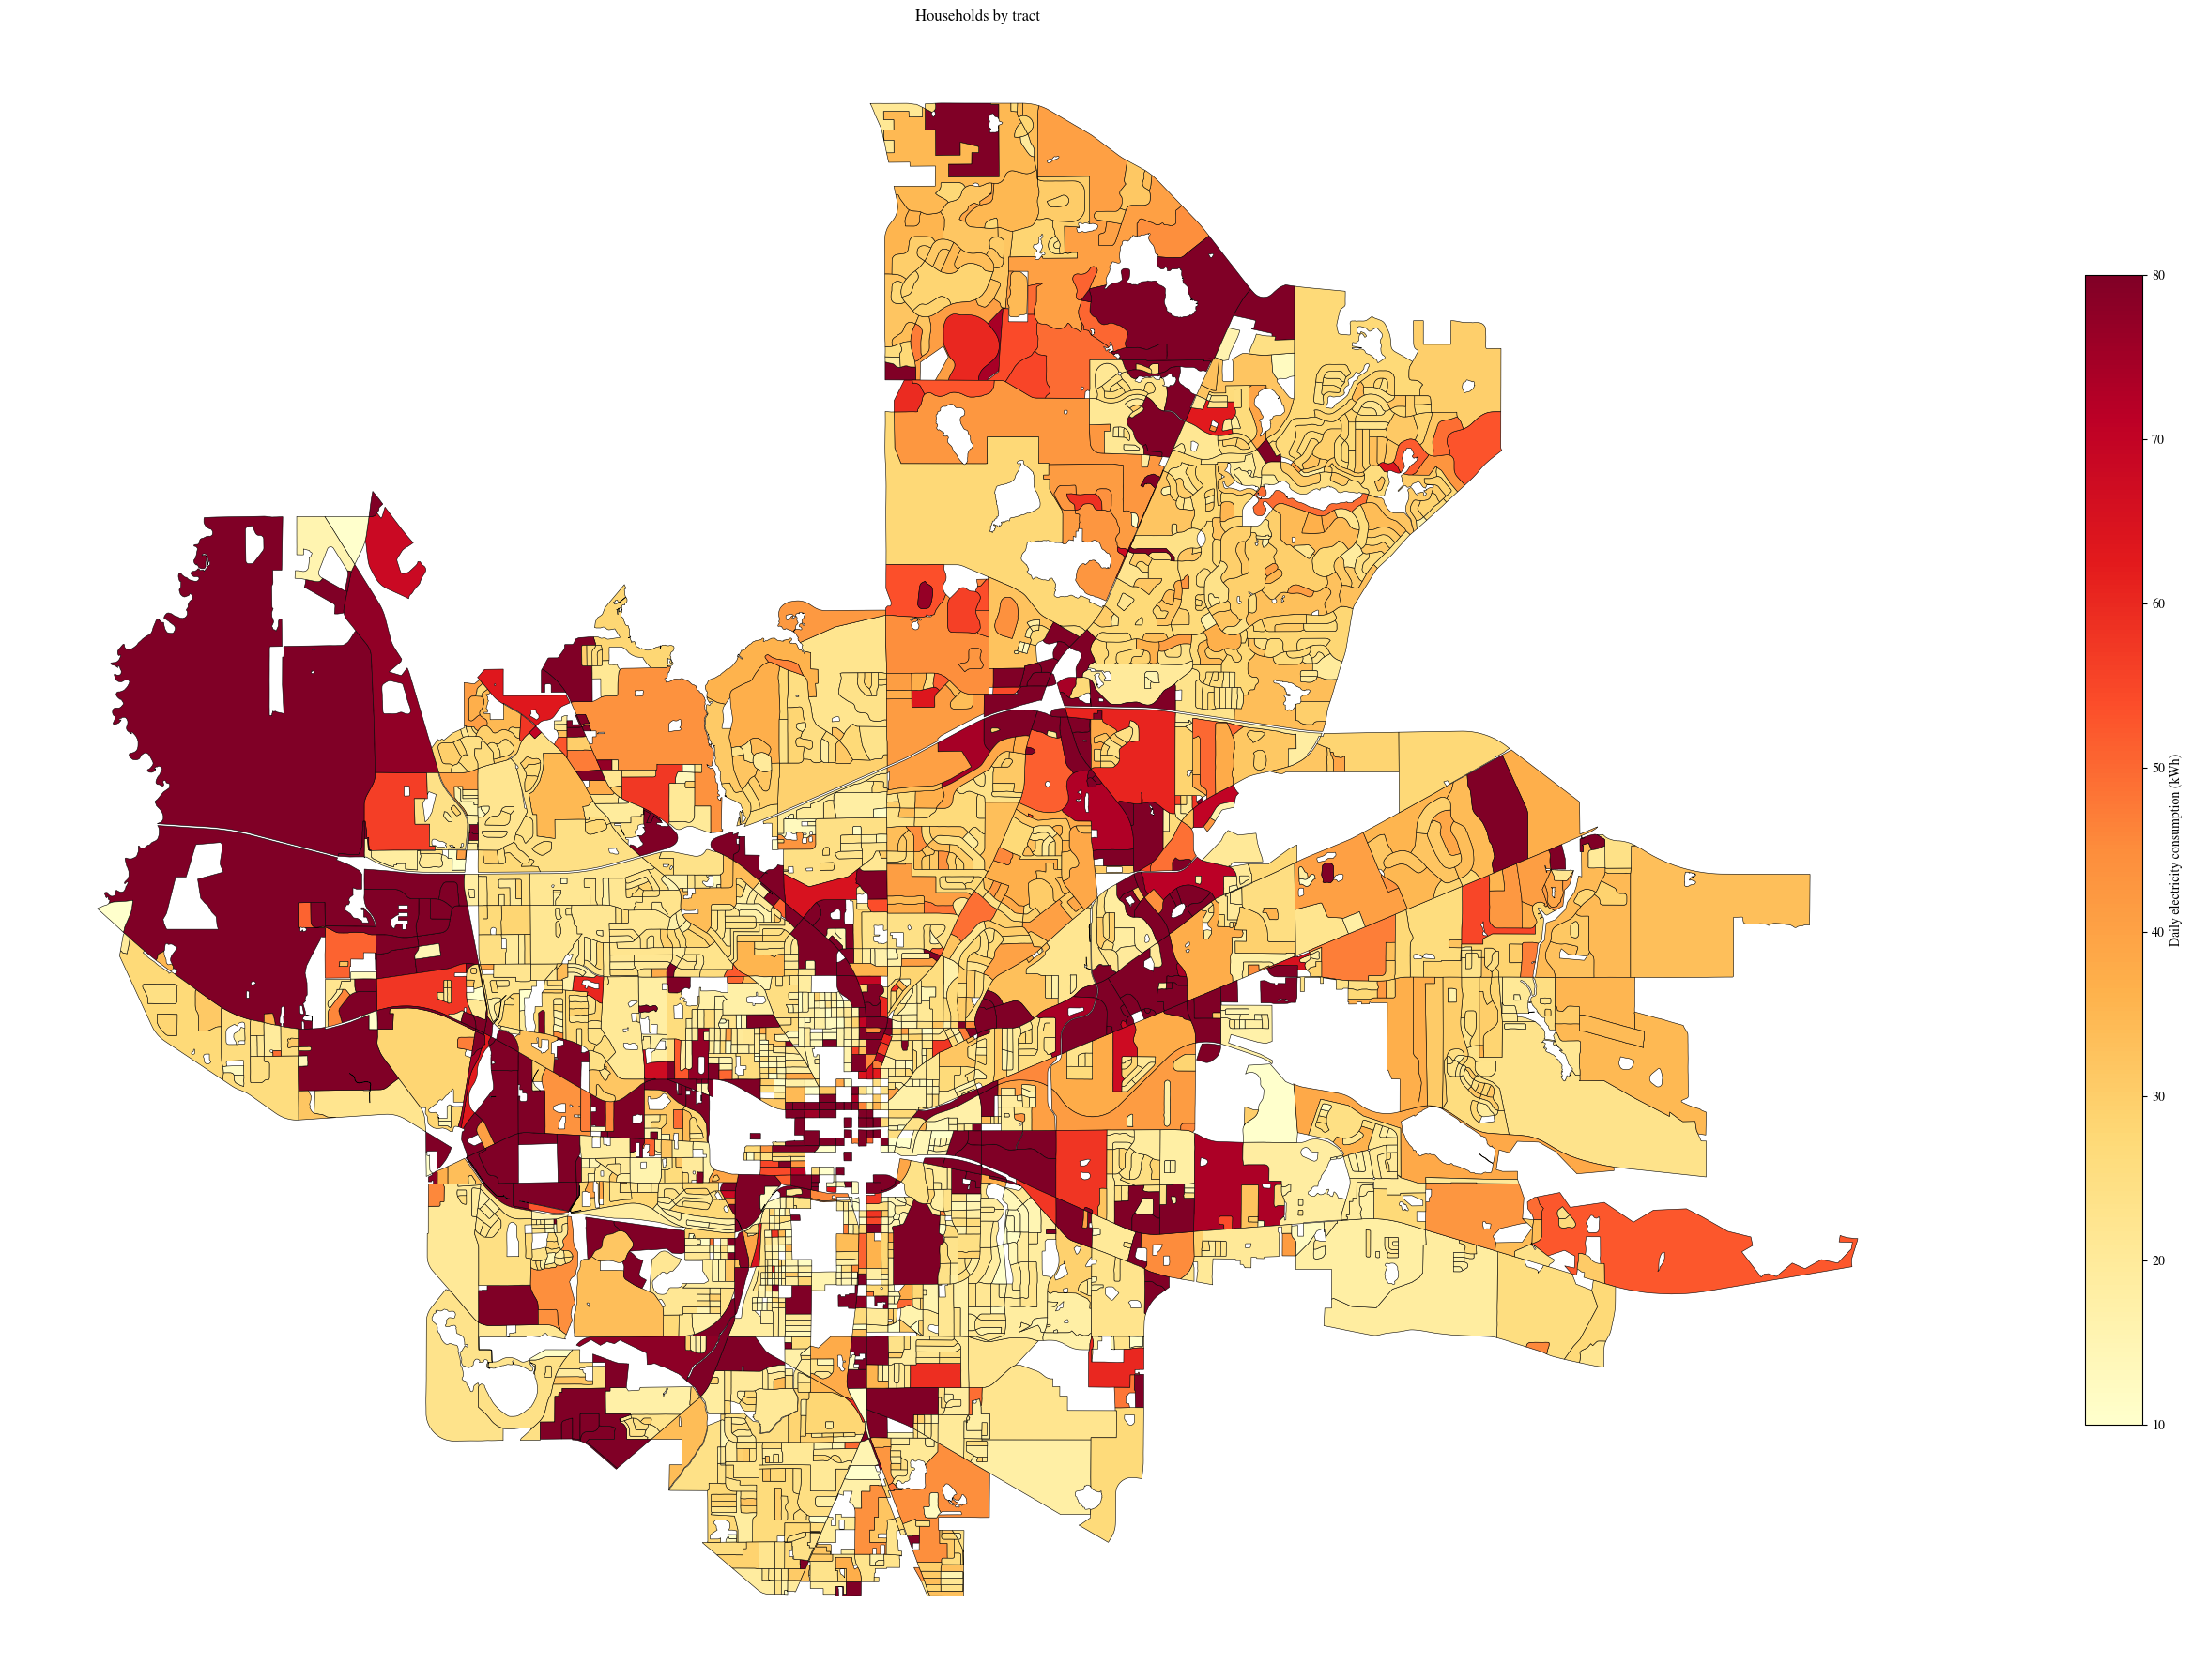

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(30, 18))
# 制图字段（有人口列时可改为 "households"）
color_col = "daily_kwh"
geo_data.plot(
    ax=ax,
    column=color_col,
    cmap="YlOrRd",
    legend=True,
    vmin=10,
    vmax=80,
    legend_kwds={
        "label": "Daily electricity consumption (kWh)",
        "orientation": "vertical",
        "shrink": 0.7,
    },
    edgecolor="black",
    linewidth=0.4,
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
ax.set_title("Households by tract")
ax.set_axis_off()
plt.tight_layout()
plt.show()